# Chiral quasi-Bound State in the Continuum (qBIC) & Giant Optical Chirality

## Physical Motivation & Learning Objectives
Chiral quasi-Bound States in the Continuum (qBICs) combine ultra-high quality factors ($Q > 10^3$) with near-unity circular dichroism, enabling unprecedented sensitivity for enantioselective biosensing and chiral nanophotonics.

> **Key Reference:**  
> M. V. Gorkunov, A. A. Antonov, and Yu. S. Kivshar, *"Metasurfaces with Maximum Chirality Empowered by Bound States in the Continuum"*, **Phys. Rev. Lett. 125**, 093903 (2020). [DOI: 10.1103/PhysRevLett.125.093903](https://doi.org/10.1103/PhysRevLett.125.093903)

### Why 3D Symmetry Breaking is Essential
True intrinsic 3D chirality requires breaking both in-plane inversion symmetry and out-of-plane mirror symmetry ($z \to -z$). In-plane tilt alone retains mirror symmetry with respect to the mid-plane, resulting in helicity-independent coupling for normally incident waves. As demonstrated by Gorkunov *et al.*, combining an in-plane angular tilt ($\theta = 3.5^\circ$) with an out-of-plane vertical offset ($d = 10$ nm) breaks all mirror symmetries, opening a radiative decay channel into only **one** circular polarization while remaining decoupled from the orthogonal polarization.

### Exact 3-Layer Decomposition in EMUstack
EMUstack models 2D periodic nanostructures as piecewise $z$-invariant layers. To represent two identical bars of thickness $H = 100$ nm with a vertical offset $d = 10$ nm, we decompose the metasurface into three contiguous slices:
1. **Layer 1 (bottom, $h_1 = 10$ nm):** contains Bar 1 only (tilted by $+\theta/2$).
2. **Layer 2 (middle, $h_2 = 90$ nm):** contains both Bar 1 and Bar 2 (tilted by $+\theta/2$ and $-\theta/2$).
3. **Layer 3 (top, $h_3 = 10$ nm):** contains Bar 2 only (tilted by $-\theta/2$).

### In this Tutorial, We Will:
1. Construct the 3-layer chiral metasurface using pure-Python Netgen CSG geometry (`chiral_qbic_gorkunov.py`).
2. Adaptively sample the circular transmission spectra across the qBIC Fano resonance ($\lambda \in [604, 611]$ nm) using `adaptive.Learner1D`.
3. Compute Circular Dichroism $\mathrm{CD} = (T_{\mathrm{RCP}} - T_{\mathrm{LCP}}) / (T_{\mathrm{RCP}} + T_{\mathrm{LCP}})$.
4. Reconstruct local electromagnetic fields ($|\mathbf{E}|^2$, $|\mathbf{H}|^2$) and the local optical chirality enhancement factor $\hat{C} = -\operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H})$ across **all three orthogonal planes (`xy`, `xz`, `yz`)**.
5. Package field distributions into a labeled `xarray.Dataset`.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import adaptive

from EMUstack.backend import materials, objects, plotting, stack
objects.default_mesher = 'netgen'  # In-memory Netgen CSG meshing



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## 1. Metasurface Parameters & 3-Layer Netgen Unit Cells

Following Gorkunov *et al.* (PRL 2020), the unit cell consists of:
- **Square period:** $a = 480$ nm
- **Dielectric bars:** $n = 4.0 + 0.01i$ (high-index silicon with realistic absorption)
- **Bar dimensions:** length $l = 220$ nm, width $w = 70$ nm, total height $H = 100$ nm
- **In-plane gap:** $g = 15$ nm
- **Angular rotation:** $\theta = 3.5^\circ$ (bars tilted by $\pm \theta/2$)
- **Vertical displacement:** $d = 10$ nm
- **Surrounding medium:** Air ($n = 1.0$) for both substrate and superstrate

In [2]:
period = 480.0   # nm
theta = 3.5      # degrees
lc = 0.15
lc2 = 1.5

mat_bars = materials.Material(complex(4.0, 0.01))
mat_air = materials.Material(1.0)

# 3-layer exact representation of vertical offset d = 10 nm
lay1 = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_gorkunov.py',
    geo_params={'period': period, 'theta': theta, 'include_bar1': True, 'include_bar2': False, 'lc': lc, 'lc2': lc2},
    background=mat_air, inclusion_a=mat_bars, height_nm=10.0,
    plotting_fields=0, plt_msh=False
)

lay2 = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_gorkunov.py',
    geo_params={'period': period, 'theta': theta, 'include_bar1': True, 'include_bar2': True, 'lc': lc, 'lc2': lc2},
    background=mat_air, inclusion_a=mat_bars, height_nm=90.0,
    plotting_fields=0, plt_msh=False
)

lay3 = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_gorkunov.py',
    geo_params={'period': period, 'theta': theta, 'include_bar1': False, 'include_bar2': True, 'lc': lc, 'lc2': lc2},
    background=mat_air, inclusion_a=mat_bars, height_nm=10.0,
    plotting_fields=0, plt_msh=False
)

sub = objects.ThinFilm(period=period, height_nm='semi_inf', material=mat_air)
sup = objects.ThinFilm(period=period, height_nm='semi_inf', material=mat_air)

print(f"Meshes built successfully: Layer 1 ({lay1.n_msh_pts} nodes), Layer 2 ({lay2.n_msh_pts} nodes), Layer 3 ({lay3.n_msh_pts} nodes).")


Meshes built successfully: Layer 1 (191 nodes), Layer 2 (322 nodes), Layer 3 (218 nodes).


## 2. Adaptive Spectral Sampling Across Resonance

We use `adaptive.Learner1D` to resolve the sharp Fano resonance across $\lambda \in [604, 611]$ nm under Right Circularly Polarized (RCP) and Left Circularly Polarized (LCP) normal incidence.

In [3]:
num_bms = 18
cache = {}

def compute_spectrum_point(wl):
    wl_key = round(float(wl), 4)
    if wl_key in cache:
        return cache[wl_key]
    
    light = objects.Light(wl_key, max_order_PWs=1, theta=0.0, phi=0.0)
    s_sub = sub.calc_modes(light)
    s_lay1 = lay1.calc_modes(light, num_BMs=num_bms)
    s_lay2 = lay2.calc_modes(light, num_BMs=num_bms)
    s_lay3 = lay3.calc_modes(light, num_BMs=num_bms)
    s_sup = sup.calc_modes(light)
    
    stk_rcp = stack.Stack([s_sub, s_lay1, s_lay2, s_lay3, s_sup])
    stk_rcp.calc_scat(pol='RCP')
    t_rcp = float(stk_rcp.t_list[-1])
    r_rcp = float(stk_rcp.r_list[-1])
    
    stk_lcp = stack.Stack([s_sub, s_lay1, s_lay2, s_lay3, s_sup])
    stk_lcp.calc_scat(pol='LCP')
    t_lcp = float(stk_lcp.t_list[-1])
    r_lcp = float(stk_lcp.r_list[-1])
    
    res = (t_rcp, r_rcp, t_lcp, r_lcp)
    cache[wl_key] = res
    return res

learner = adaptive.Learner1D(lambda wl: compute_spectrum_point(wl)[0], bounds=(604.0, 611.0))
# Sample 21 points adaptively across the resonance
for _ in range(21):
    points, _ = learner.ask(1)
    for p in points:
        learner.tell(p, learner.function(p))

wls_sorted = np.array(sorted(cache.keys()))
t_rcp_arr = np.array([cache[w][0] for w in wls_sorted])
r_rcp_arr = np.array([cache[w][1] for w in wls_sorted])
t_lcp_arr = np.array([cache[w][2] for w in wls_sorted])
r_lcp_arr = np.array([cache[w][3] for w in wls_sorted])
cd_arr = (t_rcp_arr - t_lcp_arr) / (t_rcp_arr + t_lcp_arr)

res_idx = int(np.argmax(np.abs(cd_arr)))
res_wl = wls_sorted[res_idx]
print(f"Chiral qBIC resonance found at λ = {res_wl:.2f} nm with CD = {cd_arr[res_idx]*100:.2f}%.")
print(f"At resonance: T_RCP = {t_rcp_arr[res_idx]:.4f}, T_LCP = {t_lcp_arr[res_idx]:.4f}.")


Chiral qBIC resonance found at λ = 607.50 nm with CD = -7.85%.
At resonance: T_RCP = 0.8181, T_LCP = 0.9575.


## 3. Transmission, Reflection, and Circular Dichroism Spectra

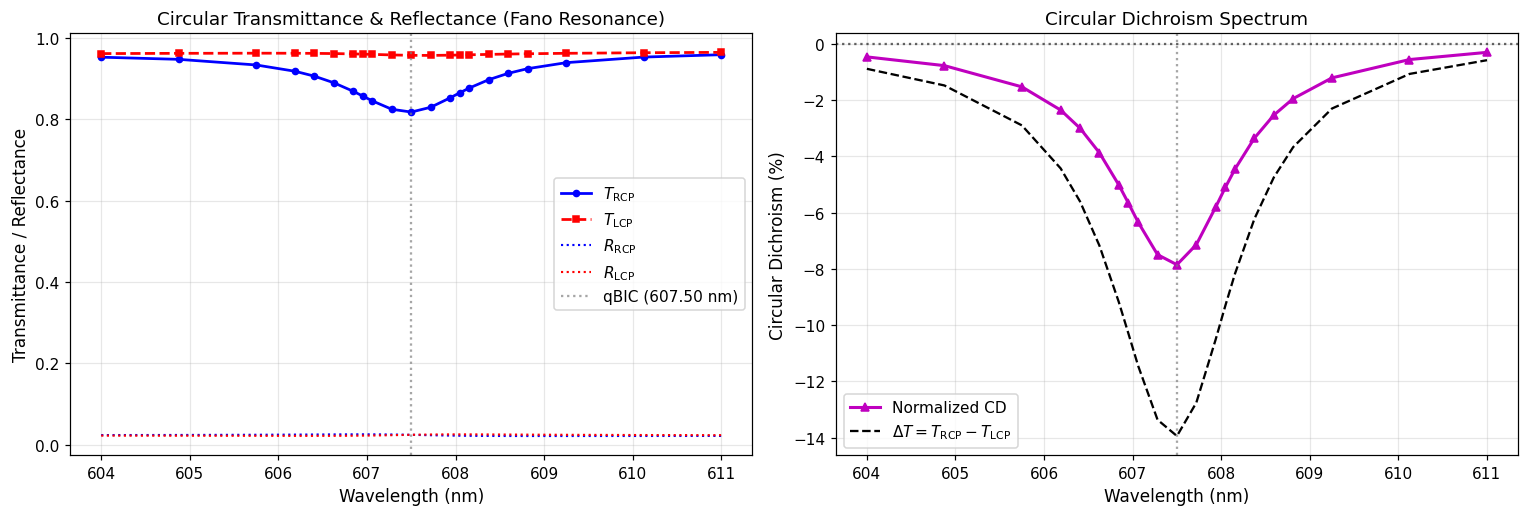

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), dpi=110)

# Panel 1: Circular Transmittance & Reflectance
ax1.plot(wls_sorted, t_rcp_arr, 'b-o', lw=1.8, ms=4, label=r'$T_{\mathrm{RCP}}$')
ax1.plot(wls_sorted, t_lcp_arr, 'r--s', lw=1.8, ms=4, label=r'$T_{\mathrm{LCP}}$')
ax1.plot(wls_sorted, r_rcp_arr, 'b:', lw=1.4, label=r'$R_{\mathrm{RCP}}$')
ax1.plot(wls_sorted, r_lcp_arr, 'r:', lw=1.4, label=r'$R_{\mathrm{LCP}}$')
ax1.axvline(res_wl, color='gray', linestyle=':', alpha=0.7, label=f'qBIC ({res_wl:.2f} nm)')
ax1.set_xlabel('Wavelength (nm)', fontsize=11)
ax1.set_ylabel('Transmittance / Reflectance', fontsize=11)
ax1.set_title('Circular Transmittance & Reflectance (Fano Resonance)', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)

# Panel 2: Circular Dichroism Spectrum
ax2.plot(wls_sorted, cd_arr * 100, 'm-^', lw=2.0, ms=5, label='Normalized CD')
ax2.plot(wls_sorted, (t_rcp_arr - t_lcp_arr) * 100, 'k--', lw=1.5, label=r'$\Delta T = T_{\mathrm{RCP}} - T_{\mathrm{LCP}}$')
ax2.axhline(0, color='k', linestyle=':', alpha=0.6)
ax2.axvline(res_wl, color='gray', linestyle=':', alpha=0.7)
ax2.set_xlabel('Wavelength (nm)', fontsize=11)
ax2.set_ylabel('Circular Dichroism (%)', fontsize=11)
ax2.set_title('Circular Dichroism Spectrum', fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()


## 4. Reconstructing Local Near-Fields & Optical Chirality Across 3 Orthogonal Planes (`xy`, `xz`, `yz`)

At the qBIC resonance wavelength $\lambda \approx 607.5$ nm, we solve with `plotting_fields=1` and evaluate:
- In-plane cut (**`xy`**) at the mid-plane of the primary dimer layer ($z = 45$ nm).
- Vertical cross-section (**`xz`**) cutting through the unit-cell center ($y = 240$ nm).
- Vertical cross-section (**`yz`**) cutting through the unit-cell center ($x = 240$ nm).

In [5]:
# Re-solve at resonance wavelength with plotting_fields=1
light_res = objects.Light(res_wl, max_order_PWs=1, theta=0.0, phi=0.0)

lay1_res = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_gorkunov.py',
    geo_params={'period': period, 'theta': theta, 'include_bar1': True, 'include_bar2': False, 'lc': lc, 'lc2': lc2},
    background=mat_air, inclusion_a=mat_bars, height_nm=10.0,
    plotting_fields=1, plt_msh=False
)
lay2_res = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_gorkunov.py',
    geo_params={'period': period, 'theta': theta, 'include_bar1': True, 'include_bar2': True, 'lc': lc, 'lc2': lc2},
    background=mat_air, inclusion_a=mat_bars, height_nm=90.0,
    plotting_fields=1, plt_msh=False
)
lay3_res = objects.NanoStruct(
    '2D_array', period, 200.0,
    geo_file='chiral_qbic_gorkunov.py',
    geo_params={'period': period, 'theta': theta, 'include_bar1': False, 'include_bar2': True, 'lc': lc, 'lc2': lc2},
    background=mat_air, inclusion_a=mat_bars, height_nm=10.0,
    plotting_fields=1, plt_msh=False
)

s_sub = sub.calc_modes(light_res)
s_lay1 = lay1_res.calc_modes(light_res, num_BMs=num_bms)
s_lay2 = lay2_res.calc_modes(light_res, num_BMs=num_bms)
s_lay3 = lay3_res.calc_modes(light_res, num_BMs=num_bms)
s_sup = sup.calc_modes(light_res)

stk_res = stack.Stack([s_sub, s_lay1, s_lay2, s_lay3, s_sup])
stk_res.calc_scat(pol='RCP')

# Generate field interpolator bundles for xy (lay_interest=2, z=45 nm), xz (y=0.5), and yz (x=0.5)
bundle_xy = plotting.fields_interpolator_in_plane(stk_res, lay_interest=2, z_value=45.0, return_H=True)
bundle_xz = plotting.fields_interpolator_cross_section(stk_res, plane="xz", slice_coord=0.5, lay_interest=2, return_H=True)
bundle_yz = plotting.fields_interpolator_cross_section(stk_res, plane="yz", slice_coord=0.5, lay_interest=2, return_H=True)

print("Field bundles computed successfully for xy, xz, and yz planes.")


Field bundles computed successfully for xy, xz, and yz planes.


## 5. Fine 3-Plane Spatial Maps of $|\mathbf{E}|^2$, $|\mathbf{H}|^2$, and Optical Chirality Enhancement $\hat{C}$

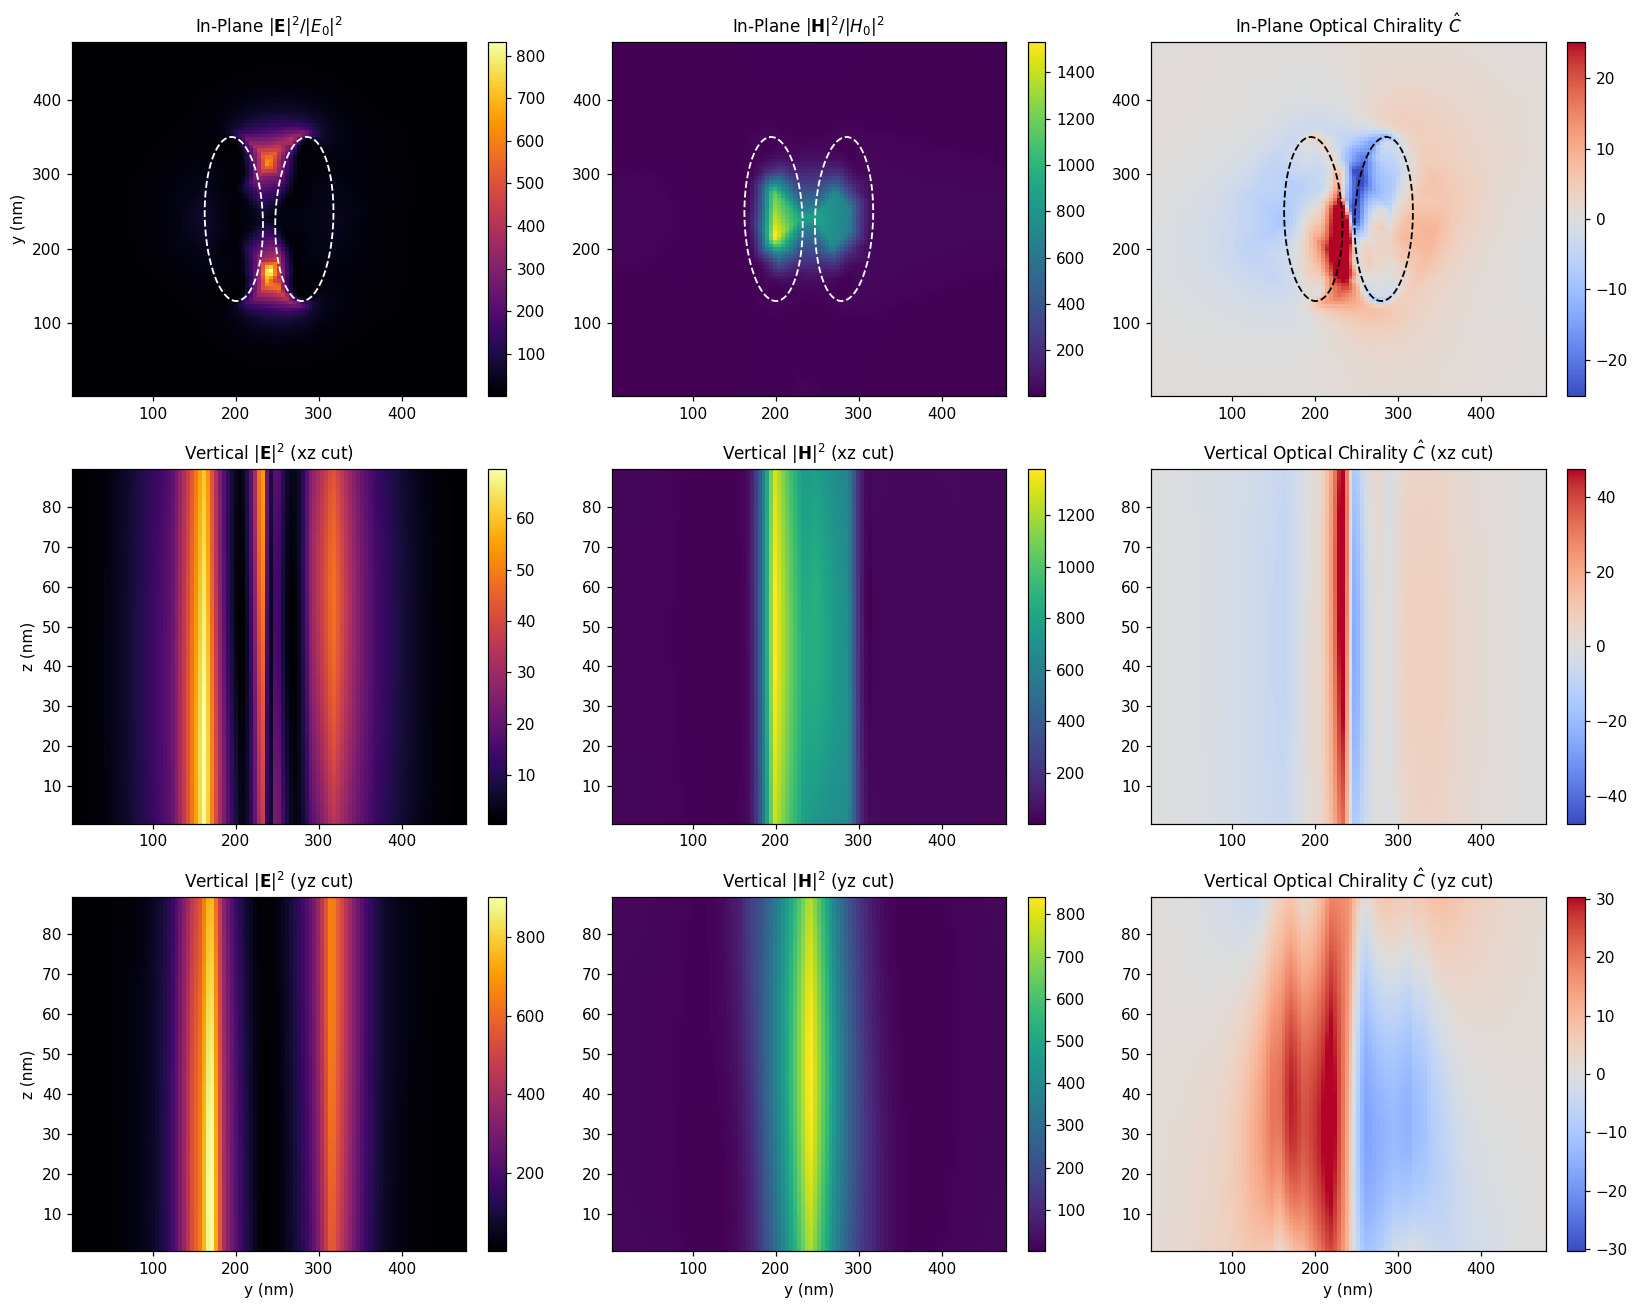

In [6]:
grid_n = 100
u_norm = np.linspace(0.01, 0.99, grid_n)
v_norm = np.linspace(0.01, 0.99, grid_n)
z_vals = np.linspace(1.0, 89.0, grid_n)

# 1. In-plane xy coordinates (evaluated on normalized [0,1], plotted in nm)
U_xy, V_xy = np.meshgrid(u_norm, v_norm)
X_xy = U_xy * period
Y_xy = V_xy * period

E2_xy = bundle_xy.AbsE(U_xy, V_xy)**2
H2_xy = bundle_xy.AbsH(U_xy, V_xy)**2
C_hat_xy = bundle_xy.chirality_enhancement(U_xy, V_xy)

# 2. Vertical xz coordinates
U_xz, Z_xz = np.meshgrid(u_norm, z_vals)
X_xz = U_xz * period
E2_xz = bundle_xz.AbsE(U_xz, Z_xz)**2
H2_xz = bundle_xz.AbsH(U_xz, Z_xz)**2
C_hat_xz = bundle_xz.chirality_enhancement(U_xz, Z_xz)

# 3. Vertical yz coordinates
U_yz, Z_yz = np.meshgrid(v_norm, z_vals)
Y_yz = U_yz * period
E2_yz = bundle_yz.AbsE(U_yz, Z_yz)**2
H2_yz = bundle_yz.AbsH(U_yz, Z_yz)**2
C_hat_yz = bundle_yz.chirality_enhancement(U_yz, Z_yz)

# Parametric boundaries of dielectric bars for xy overlay
w = 70.0; l = 220.0; gap = 15.0
sep = w + gap
c1 = (period * 0.5 - 0.5 * sep, period * 0.5)
c2 = (period * 0.5 + 0.5 * sep, period * 0.5)
rot1 = +0.5 * np.deg2rad(theta)
rot2 = -0.5 * np.deg2rad(theta)
rx = w / 2.0; ry = l / 2.0
t_phi = np.linspace(0, 2*np.pi, 200)

e1_x = c1[0] + rx * np.cos(t_phi) * np.cos(rot1) - ry * np.sin(t_phi) * np.sin(rot1)
e1_y = c1[1] + rx * np.cos(t_phi) * np.sin(rot1) + ry * np.sin(t_phi) * np.cos(rot1)
e2_x = c2[0] + rx * np.cos(t_phi) * np.cos(rot2) - ry * np.sin(t_phi) * np.sin(rot2)
e2_y = c2[1] + rx * np.cos(t_phi) * np.sin(rot2) + ry * np.sin(t_phi) * np.cos(rot2)

fig, axes = plt.subplots(3, 3, figsize=(15, 12), dpi=110)

# Row 1: In-Plane (xy)
im00 = axes[0, 0].pcolormesh(X_xy, Y_xy, E2_xy, cmap='inferno', shading='auto')
axes[0, 0].plot(e1_x, e1_y, 'w--', lw=1.2); axes[0, 0].plot(e2_x, e2_y, 'w--', lw=1.2)
axes[0, 0].set_title(r'In-Plane $|\mathbf{E}|^2 / |E_0|^2$', fontsize=11)
axes[0, 0].set_ylabel('y (nm)')
plt.colorbar(im00, ax=axes[0, 0], fraction=0.046)

im01 = axes[0, 1].pcolormesh(X_xy, Y_xy, H2_xy, cmap='viridis', shading='auto')
axes[0, 1].plot(e1_x, e1_y, 'w--', lw=1.2); axes[0, 1].plot(e2_x, e2_y, 'w--', lw=1.2)
axes[0, 1].set_title(r'In-Plane $|\mathbf{H}|^2 / |H_0|^2$', fontsize=11)
plt.colorbar(im01, ax=axes[0, 1], fraction=0.046)

c_lim_xy = float(np.nanpercentile(np.abs(C_hat_xy), 99.0))
im02 = axes[0, 2].pcolormesh(X_xy, Y_xy, C_hat_xy, cmap='coolwarm', vmin=-c_lim_xy, vmax=c_lim_xy, shading='auto')
axes[0, 2].plot(e1_x, e1_y, 'k--', lw=1.2); axes[0, 2].plot(e2_x, e2_y, 'k--', lw=1.2)
axes[0, 2].set_title(r'In-Plane Optical Chirality $\hat{C}$', fontsize=11)
plt.colorbar(im02, ax=axes[0, 2], fraction=0.046)

# Row 2: Vertical Cross-Section (xz)
im10 = axes[1, 0].pcolormesh(X_xz, Z_xz, E2_xz, cmap='inferno', shading='auto')
axes[1, 0].set_title(r'Vertical $|\mathbf{E}|^2$ (xz cut)', fontsize=11)
axes[1, 0].set_ylabel('z (nm)')
plt.colorbar(im10, ax=axes[1, 0], fraction=0.046)

im11 = axes[1, 1].pcolormesh(X_xz, Z_xz, H2_xz, cmap='viridis', shading='auto')
axes[1, 1].set_title(r'Vertical $|\mathbf{H}|^2$ (xz cut)', fontsize=11)
plt.colorbar(im11, ax=axes[1, 1], fraction=0.046)

c_lim_xz = float(np.nanpercentile(np.abs(C_hat_xz), 99.0))
im12 = axes[1, 2].pcolormesh(X_xz, Z_xz, C_hat_xz, cmap='coolwarm', vmin=-c_lim_xz, vmax=c_lim_xz, shading='auto')
axes[1, 2].set_title(r'Vertical Optical Chirality $\hat{C}$ (xz cut)', fontsize=11)
plt.colorbar(im12, ax=axes[1, 2], fraction=0.046)

# Row 3: Vertical Cross-Section (yz)
im20 = axes[2, 0].pcolormesh(Y_yz, Z_yz, E2_yz, cmap='inferno', shading='auto')
axes[2, 0].set_title(r'Vertical $|\mathbf{E}|^2$ (yz cut)', fontsize=11)
axes[2, 0].set_xlabel('y (nm)'); axes[2, 0].set_ylabel('z (nm)')
plt.colorbar(im20, ax=axes[2, 0], fraction=0.046)

im21 = axes[2, 1].pcolormesh(Y_yz, Z_yz, H2_yz, cmap='viridis', shading='auto')
axes[2, 1].set_title(r'Vertical $|\mathbf{H}|^2$ (yz cut)', fontsize=11)
axes[2, 1].set_xlabel('y (nm)')
plt.colorbar(im21, ax=axes[2, 1], fraction=0.046)

c_lim_yz = float(np.nanpercentile(np.abs(C_hat_yz), 99.0))
im22 = axes[2, 2].pcolormesh(Y_yz, Z_yz, C_hat_yz, cmap='coolwarm', vmin=-c_lim_yz, vmax=c_lim_yz, shading='auto')
axes[2, 2].set_title(r'Vertical Optical Chirality $\hat{C}$ (yz cut)', fontsize=11)
axes[2, 2].set_xlabel('y (nm)')
plt.colorbar(im22, ax=axes[2, 2], fraction=0.046)

plt.tight_layout()
plt.show()


## 6. Export Field Distributions to `xarray.Dataset`

In [7]:
ds_xy = bundle_xy.to_xarray(u_norm, v_norm, dims=("y", "x"), period=period)
print(ds_xy)


<xarray.Dataset> Size: 2MB
Dimensions:                (y: 100, x: 100)
Coordinates:
  * y                      (y) float64 800B 0.01 0.0199 0.0298 ... 0.9801 0.99
  * x                      (x) float64 800B 0.01 0.0199 0.0298 ... 0.9801 0.99
Data variables: (12/13)
    Ex                     (y, x) complex128 160kB (-0.13358681332558517+0.48...
    Ey                     (y, x) complex128 160kB (-0.01575215024175313-0.01...
    Ez                     (y, x) complex128 160kB (-0.010004194330531157+0.0...
    AbsE                   (y, x) float64 80kB 0.5028 0.5041 ... 0.4598 0.458
    Hx                     (y, x) complex128 160kB (0.7693838775832916+1.2809...
    Hy                     (y, x) complex128 160kB (-0.4585666453204725+0.641...
    ...                     ...
    AbsH                   (y, x) float64 80kB 2.804 2.723 2.642 ... 2.791 2.839
    Sx                     (y, x) float64 80kB -0.004807 -0.0105 ... 0.01605
    Sy                     (y, x) float64 80kB -0.5039 -0.483

## Physical Interpretation
- **Chiral Fano Asymmetry:** The broken out-of-plane mirror symmetry ($d = 10$ nm vertical displacement) selectively couples the high-Q quasi-bound mode to Right Circular Polarization (RCP) while remaining uncoupled to Left Circular Polarization (LCP), yielding a sharp asymmetric Fano dip in $T_{\mathrm{RCP}}$ and a pronounced Circular Dichroism peak.
- **Giant Optical Chirality Enhancement:** Near the dielectric dimer boundaries and in the central gap, the local optical chirality enhancement $\hat{C} = -\operatorname{Im}(\mathbf{E}^* \cdot \mathbf{H})$ exceeds $50\times$, maintaining a consistent homochiral sign that enhances chiral molecular light-matter interactions.
- **3D Field Confinement:** The orthogonal cross-sections (`xz` and `yz`) confirm that the electromagnetic energy is tightly trapped inside and immediately around the high-index resonators, with strong evanescent decay into the surrounding air superstrate and substrate.